# Esplorazione del dataset BRIGHT — DFC2025 Track 2

## Obiettivo

Questo notebook prepara il primo passo verso la riproduzione della
soluzione vincitrice del Data Fusion Contest 2025, Track 2:
comprendere i dati e il modo in cui saranno forniti al modello.

Per ciascun esempio esaminiamo tre elementi:

- **Immagine ottica prima del disastro:** mostra l'aspetto della zona
  prima dell'evento.
- **Immagine SAR dopo il disastro:** contiene le osservazioni radar
  successive all'evento.
- **Maschera del danno di riferimento:** contiene le etichette con cui
  addestrare il modello e confrontare le sue previsioni.

In questa fase non addestriamo una rete e non produciamo previsioni.
Le maschere che apriremo sono annotazioni già presenti nel dataset.

Per iniziare utilizziamo soltanto tre esempi del training set.
Questo piccolo campione serve a verificare il caricamento dei dati;
non è sufficiente per valutare le prestazioni di un modello.

## 1. Selezione degli esempi dalla lista ufficiale

Il repository BRIGHT contiene le liste degli esempi assegnati alle
diverse suddivisioni della competizione. Questi file di testo
contengono identificativi, non le immagini.

Leggiamo `train_set.txt` e selezioniamo i primi tre identificativi.
La scelta è semplice e ripetibile: rieseguendo il notebook con la
stessa lista otteniamo gli stessi esempi.

Gli esempi selezionati appartengono all'evento Bata explosion.
Non rappresentano quindi la varietà di eventi presente nell'intero dataset.

### Cosa fa il codice

1. Individua la cartella di lavoro del notebook.
2. Costruisce il percorso della lista di training.
3. Verifica che il file esista.
4. Legge gli identificativi, eliminando eventuali righe vuote.
5. Conserva i primi tre nella variabile `esempi`.

Il numero totale stampato indica gli esempi elencati nella lista,
non quelli già scaricati sul computer.

In [5]:
from pathlib import Path

# Cartella da cui viene eseguito il notebook
PROGETTO = Path.cwd()
print("Cartella di lavoro:", PROGETTO)

# Elenco ufficiale degli esempi di training
file_training = (
    PROGETTO
    / "BRIGHT"
    / "bda_benchmark"
    / "dataset"
    / "splitname"
    / "dfc25"
    / "train_set.txt"
)

if not file_training.is_file():
    raise FileNotFoundError(
        "Lista di training non trovata. "
        "Controlla la cartella di lavoro stampata sopra."
    )

nomi_training = file_training.read_text().splitlines()
nomi_training = [nome.strip() for nome in nomi_training if nome.strip()]

# Selezioniamo tre esempi per l'esplorazione
esempi = nomi_training[:3]

print("Numero di esempi nella lista di training:", len(nomi_training))
print("\nEsempi selezionati:")
for nome in esempi:
    print(nome)

Cartella di lavoro: /Users/antonyogrossi/tesi/riproduzione_dfc2025
Numero di esempi nella lista di training: 2229

Esempi selezionati:
bata-explosion_00000049
bata-explosion_00000014
bata-explosion_00000047


## 2. Preparazione del download selettivo

Le immagini sono distribuite in un archivio ZIP online di circa
10,2 GB. Per questa esplorazione ci servono soltanto nove file:
tre per ciascuno dei tre esempi selezionati.

Installiamo `remotezip`, una libreria che permette di leggere
l'indice di uno ZIP remoto e recuperarne singoli file, quando il
server supporta questo tipo di accesso.

Il comando `%pip` installa la libreria nell'ambiente Python
utilizzato dal notebook. Questa cella non scarica il dataset.

In [6]:
%pip install remotezip

Note: you may need to restart the kernel to use updated packages.


## 3. Ricerca dei file nell'archivio

Ogni identificativo collega tre file relativi allo stesso esempio:

| Cartella | Suffisso del file | Contenuto |
|---|---|---|
| `pre-event` | `_pre_disaster.tif` | Immagine ottica prima del disastro |
| `post-event` | `_post_disaster.tif` | Immagine SAR dopo il disastro |
| `target` | `_building_damage.tif` | Maschera del danno di riferimento |

Il codice legge l'indice dell'archivio online e cerca i file TIFF
il cui nome inizia con uno degli identificativi selezionati.

In questo passaggio vengono trasferite le informazioni necessarie
a leggere l'indice, ma non vengono ancora scaricate le nove immagini.

La variabile `file_selezionati` conserva i percorsi dei file
nell'archivio: li utilizzeremo nel passaggio di download.

In [7]:
from remotezip import RemoteZip

URL_ARCHIVIO = (
    "https://huggingface.co/datasets/Kullervo/BRIGHT/"
    "resolve/main/dfc25_track2_trainval.zip"
)

print("Lettura dell'elenco dei file online...", flush=True)

with RemoteZip(
    URL_ARCHIVIO,
    initial_buffer_size=2 * 1024 * 1024,
    timeout=60,
) as archivio:

    file_selezionati = [
        elemento.filename
        for elemento in archivio.infolist()
        if not elemento.is_dir()
        and elemento.filename.lower().endswith(".tif")
        and any(
            Path(elemento.filename).name.startswith(nome + "_")
            for nome in esempi
        )
    ]

print("File trovati:", len(file_selezionati))

for percorso in sorted(file_selezionati):
    print(percorso)

Lettura dell'elenco dei file online...
File trovati: 9
dfc25_track2_trainval/train/post-event/bata-explosion_00000014_post_disaster.tif
dfc25_track2_trainval/train/post-event/bata-explosion_00000047_post_disaster.tif
dfc25_track2_trainval/train/post-event/bata-explosion_00000049_post_disaster.tif
dfc25_track2_trainval/train/pre-event/bata-explosion_00000014_pre_disaster.tif
dfc25_track2_trainval/train/pre-event/bata-explosion_00000047_pre_disaster.tif
dfc25_track2_trainval/train/pre-event/bata-explosion_00000049_pre_disaster.tif
dfc25_track2_trainval/train/target/bata-explosion_00000014_building_damage.tif
dfc25_track2_trainval/train/target/bata-explosion_00000047_building_damage.tif
dfc25_track2_trainval/train/target/bata-explosion_00000049_building_damage.tif


### Risultato della ricerca

Sono stati trovati nove file, tutti nella cartella `train`:

- tre immagini ottiche;
- tre immagini SAR;
- tre maschere del danno.

Gli identificativi sono `bata-explosion_00000049`,
`bata-explosion_00000014` e `bata-explosion_00000047`.

Per ogni identificativo sono presenti tutti e tre i file attesi.
Abbiamo verificato la presenza dei file nell'archivio; dopo il
download controlleremo anche dimensioni, bande e valori effettivi.

## 4. Download dei tre esempi

Recuperiamo dall'archivio online soltanto i nove file selezionati.

Li salviamo nella cartella `dati/bright_esempi`, suddivisi in:

- `pre-event`: immagini ottiche prima del disastro;
- `post-event`: immagini SAR dopo il disastro;
- `target`: maschere del danno di riferimento.

I file vengono decompressi e salvati senza modificare i valori
dei pixel o le informazioni geografiche.

Il codice controlla dimensione e CRC dei file: il CRC è un controllo
di integrità che aiuta a rilevare dati incompleti o danneggiati.
Se un file già presente supera questi controlli, non viene scaricato
nuovamente.

In [8]:
from pathlib import PurePosixPath
import zlib

CARTELLA_DATI = PROGETTO / "dati" / "bright_esempi"
CARTELLA_DATI.mkdir(parents=True, exist_ok=True)

with RemoteZip(
    URL_ARCHIVIO,
    initial_buffer_size=2 * 1024 * 1024,
    timeout=60,
) as archivio:

    for percorso_remoto in sorted(file_selezionati):
        informazioni = archivio.getinfo(percorso_remoto)
        percorso = PurePosixPath(percorso_remoto)

        # La cartella immediatamente precedente al nome del file:
        # pre-event, post-event oppure target
        categoria = percorso.parent.name

        if categoria not in {"pre-event", "post-event", "target"}:
            raise ValueError(f"Cartella inattesa: {categoria}")

        destinazione = CARTELLA_DATI / categoria / percorso.name
        destinazione.parent.mkdir(parents=True, exist_ok=True)

        # Evita di riscaricare un file già completo e integro
        if destinazione.is_file():
            contenuto_locale = destinazione.read_bytes()

            if (
                len(contenuto_locale) == informazioni.file_size
                and zlib.crc32(contenuto_locale) == informazioni.CRC
            ):
                print(f"Già presente: {categoria}/{percorso.name}", flush=True)
                continue

        print(f"Scarico: {categoria}/{percorso.name}", flush=True)

        contenuto = archivio.read(percorso_remoto)

        if (
            len(contenuto) != informazioni.file_size
            or zlib.crc32(contenuto) != informazioni.CRC
        ):
            raise RuntimeError(f"Controllo fallito: {percorso.name}")

        # Salva prima un file temporaneo, poi lo rinomina
        temporaneo = destinazione.with_suffix(".tif.part")
        temporaneo.write_bytes(contenuto)
        temporaneo.replace(destinazione)

print("\nDownload completato.")
print("Cartella dei dati:", CARTELLA_DATI)

Scarico: post-event/bata-explosion_00000014_post_disaster.tif
Scarico: post-event/bata-explosion_00000047_post_disaster.tif
Scarico: post-event/bata-explosion_00000049_post_disaster.tif
Scarico: pre-event/bata-explosion_00000014_pre_disaster.tif
Scarico: pre-event/bata-explosion_00000047_pre_disaster.tif
Scarico: pre-event/bata-explosion_00000049_pre_disaster.tif
Scarico: target/bata-explosion_00000014_building_damage.tif
Scarico: target/bata-explosion_00000047_building_damage.tif
Scarico: target/bata-explosion_00000049_building_damage.tif

Download completato.
Cartella dei dati: /Users/antonyogrossi/tesi/riproduzione_dfc2025/dati/bright_esempi


## 5. Lettura delle caratteristiche di un esempio

Apriamo i tre file del primo esempio selezionato:
immagine ottica, immagine SAR e maschera del danno.

Con Rasterio controlliamo:

- **Forma dell'array:** numero di bande, righe e colonne.
- **Tipo dei dati:** come sono memorizzati i valori, ad esempio
  interi `uint8` oppure numeri decimali.
- **CRS:** sistema di riferimento delle coordinate.
- **Risoluzione:** dimensione del pixel nelle unità del CRS.
- **NoData:** eventuale valore dichiarato per indicare dati mancanti.
- **Minimo e massimo per banda:** intervallo dei valori memorizzati.

Il minimo e il massimo vengono calcolati escludendo i pixel che
Rasterio riconosce come non validi.

Il tipo numerico e l'intervallo dei valori, da soli, non permettono
di stabilire se il SAR sia espresso in decibel: per questo occorre
consultare anche la documentazione del prodotto.

In [9]:
import rasterio

# Primo identificativo selezionato dalla lista di training
nome_esempio = esempi[0]
print("Esempio:", nome_esempio)

percorsi = {
    "Ottico pre-disastro": (
        CARTELLA_DATI / "pre-event"
        / f"{nome_esempio}_pre_disaster.tif"
    ),
    "SAR post-disastro": (
        CARTELLA_DATI / "post-event"
        / f"{nome_esempio}_post_disaster.tif"
    ),
    "Maschera del danno": (
        CARTELLA_DATI / "target"
        / f"{nome_esempio}_building_damage.tif"
    ),
}

for descrizione, percorso in percorsi.items():
    with rasterio.open(percorso) as dataset:
        valori = dataset.read(masked=True)

        print(f"\n--- {descrizione} ---")
        print("Forma (bande, righe, colonne):", valori.shape)
        print("Tipo dei dati:", dataset.dtypes)
        print("CRS:", dataset.crs)
        print("Risoluzione nelle unità del CRS:", dataset.res)
        print("NoData dichiarato:", dataset.nodata)

        for indice, banda in enumerate(valori, start=1):
            if banda.count() == 0:
                print(f"Banda {indice}: nessun pixel valido")
            else:
                print(
                    f"Banda {indice}: "
                    f"minimo = {banda.min()}, "
                    f"massimo = {banda.max()}"
                )

Esempio: bata-explosion_00000049

--- Ottico pre-disastro ---
Forma (bande, righe, colonne): (3, 1024, 1024)
Tipo dei dati: ('uint8', 'uint8', 'uint8')
CRS: EPSG:4326
Risoluzione nelle unità del CRS: (4.572424737366789e-06, 4.572424813937759e-06)
NoData dichiarato: 0.0
Banda 1: minimo = 3, massimo = 255
Banda 2: minimo = 5, massimo = 255
Banda 3: minimo = 11, massimo = 246

--- SAR post-disastro ---
Forma (bande, righe, colonne): (1, 1024, 1024)
Tipo dei dati: ('uint8',)
CRS: EPSG:4326
Risoluzione nelle unità del CRS: (4.572424737366368e-06, 4.572424813937713e-06)
NoData dichiarato: 0.0
Banda 1: minimo = 1, massimo = 255

--- Maschera del danno ---
Forma (bande, righe, colonne): (1, 1024, 1024)
Tipo dei dati: ('uint8',)
CRS: EPSG:4326
Risoluzione nelle unità del CRS: (4.572424737366368e-06, 4.572424813937713e-06)
NoData dichiarato: None
Banda 1: minimo = 0, massimo = 3


## 6. Classi presenti nella maschera

La maschera contiene un numero di classe per ogni pixel:

| Valore | Classe |
|---|---|
| 0 | Sfondo: area non annotata come edificio |
| 1 | Edificio integro |
| 2 | Edificio danneggiato |
| 3 | Edificio distrutto |

Questi valori sono etichette, non intensità luminose.
La classe "integro" descrive l'annotazione del dataset e non
costituisce una certificazione di sicurezza strutturale.

Contiamo i pixel di ogni classe per capire come sono distribuite
le etichette in questo esempio.

Attenzione: contiamo pixel, non edifici. Un edificio grande occupa
più pixel di un edificio piccolo.

Le percentuali sono calcolate sull'intera maschera, incluso lo sfondo.

In [ ]:
import numpy as np

classi = {
    0: "Sfondo",
    1: "Edificio integro",
    2: "Edificio danneggiato",
    3: "Edificio distrutto",
}

with rasterio.open(percorsi["Maschera del danno"]) as dataset:
    maschera = dataset.read(1)      # legge la prima e unica banda: otteniamo una matrice (1024, 1024).

valori, conteggi = np.unique(maschera, return_counts=True)      # trova i valori distinti e conta quante volte compare ciascuno.

# Controlliamo che non ci siano etichette inattese
valori_inattesi = set(valori.tolist()) - set(classi)

if valori_inattesi:
    raise ValueError(f"Etichette non previste: {valori_inattesi}")

conteggi_per_classe = dict(zip(valori.tolist(), conteggi.tolist()))
totale_pixel = maschera.size

print("Esempio:", nome_esempio)
print("Forma della maschera:", maschera.shape)
print("Totale pixel:", totale_pixel)
print()

for codice, descrizione in classi.items():
    numero = conteggi_per_classe.get(codice, 0)
    percentuale = 100 * numero / totale_pixel

    print(
        f"{codice} — {descrizione}: "
        f"{numero:,} pixel ({percentuale:.2f}%)"
    )

Esempio: bata-explosion_00000049
Forma della maschera: (1024, 1024)
Totale pixel: 1048576

0 — Sfondo: 919,216 pixel (87.66%)
1 — Edificio integro: 6,789 pixel (0.65%)
2 — Edificio danneggiato: 20,426 pixel (1.95%)
3 — Edificio distrutto: 102,145 pixel (9.74%)


## 7. Visualizzazione di ottico, SAR e maschera

Mostriamo affiancati i tre file dello stesso esempio:

- immagine ottica prima del disastro, a colori;
- immagine SAR dopo il disastro, in scala di grigi;
- maschera di riferimento, con un colore per classe.

Nella maschera scegliamo:
- grigio scuro per lo sfondo;
- verde per gli edifici integri;
- arancione per quelli danneggiati;
- rosso per quelli distrutti.

I colori servono soltanto alla visualizzazione: la maschera originale
continua a contenere i numeri 0, 1, 2 e 3.

Per mostrare l'immagine RGB spostiamo l'asse delle bande:
da (bande, righe, colonne) a (righe, colonne, bande).
Non cambiamo i valori dei pixel.

Visualizziamo il SAR uint8 nell'intervallo 0–255, senza convertirlo
in decibel. I pixel dichiarati non validi vengono mostrati in grigio.

La maschera è un'annotazione del dataset, non una previsione
prodotta dal nostro modello.

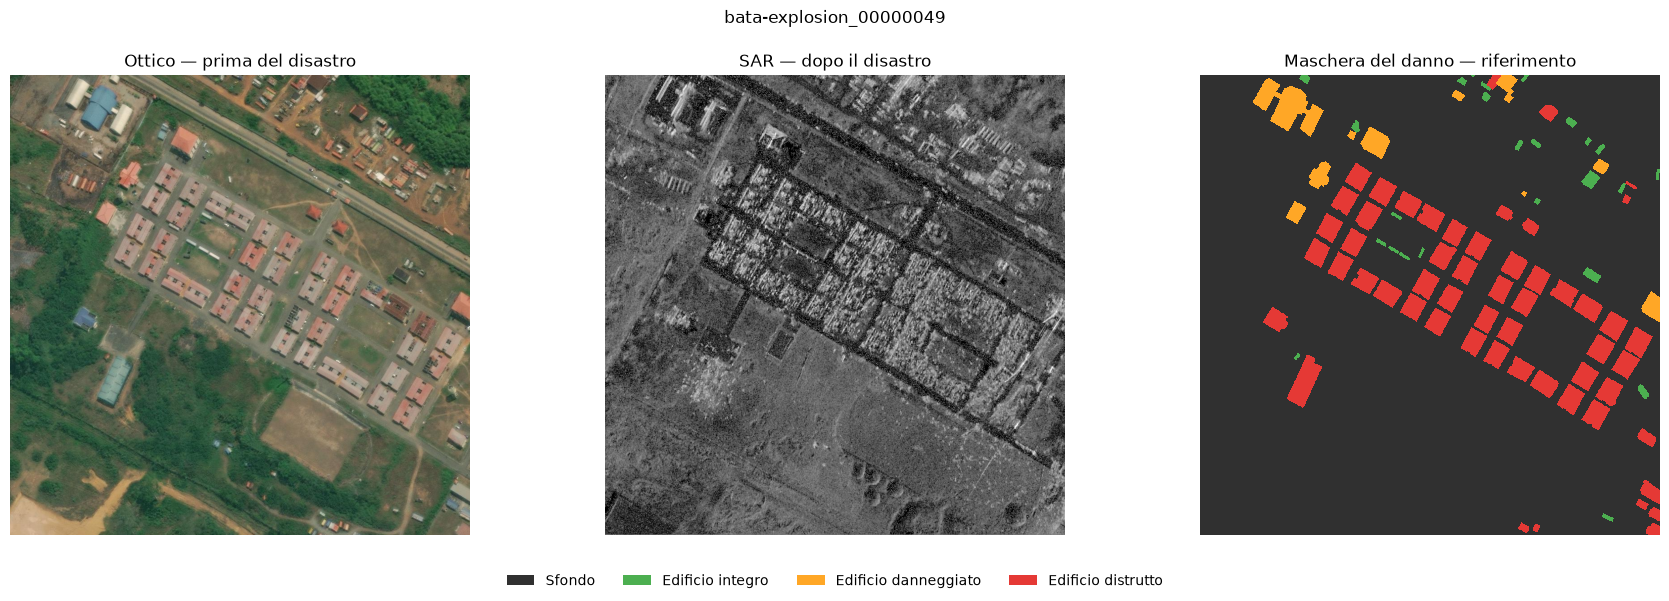

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Leggiamo l'immagine ottica e spostiamo le bande sull'ultimo asse
with rasterio.open(percorsi["Ottico pre-disastro"]) as dataset:
    ottico = dataset.read()
    validi_ottico = np.all(dataset.read_masks() > 0, axis=0)

rgb = np.moveaxis(ottico, 0, -1)

# Leggiamo il SAR conservando l'indicazione dei pixel non validi
with rasterio.open(percorsi["SAR post-disastro"]) as dataset:
    sar = dataset.read(1, masked=True)

# Colori scelti per rappresentare le classi
colori = ["#303030", "#4CAF50", "#FFA726", "#E53935"]
mappa_classi = ListedColormap(colori)
norma_classi = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    ncolors=mappa_classi.N
)

mappa_sar = plt.get_cmap("gray").copy()
mappa_sar.set_bad("#808080")

fig, assi = plt.subplots(1, 3, figsize=(18, 6))

assi[0].set_facecolor("#808080")
assi[0].imshow(rgb, alpha=validi_ottico.astype(float))
assi[0].set_title("Ottico — prima del disastro")

assi[1].imshow(sar, cmap=mappa_sar, vmin=0, vmax=255)
assi[1].set_title("SAR — dopo il disastro")

assi[2].imshow(
    maschera,
    cmap=mappa_classi,
    norm=norma_classi,
    interpolation="nearest"
)
assi[2].set_title("Maschera del danno — riferimento")

for asse in assi:
    asse.axis("off")

legenda = [
    Patch(facecolor=colori[codice], label=descrizione)
    for codice, descrizione in classi.items()
]

fig.legend(
    handles=legenda,
    loc="lower center",
    ncol=4,
    frameon=False
)

fig.suptitle(nome_esempio)
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

## 8. Verifica della griglia geografica

Per confrontare immagini e maschera pixel per pixel, controlliamo che
i tre file abbiano:

- lo stesso numero di righe e colonne;
- lo stesso sistema di riferimento (CRS);
- trasformazioni geografiche compatibili.

La trasformazione collega colonne e righe alle coordinate sul terreno.

Confrontiamo le trasformazioni ammettendo differenze numeriche
inferiori a un milionesimo di pixel, dovute alla precisione con cui
sono memorizzati i numeri.

Questo controllo verifica la griglia dichiarata nei file.
Non garantisce che ogni edificio coincida perfettamente nelle immagini:
possono rimanere differenze dovute alla geometria dei sensori o
all'allineamento delle immagini.

In [12]:
# Recuperiamo i metadati dei tre file
metadati = {}

for descrizione, percorso in percorsi.items():
    with rasterio.open(percorso) as dataset:
        metadati[descrizione] = {
            "shape": dataset.shape,
            "crs": dataset.crs,
            "transform": dataset.transform,
        }

riferimento = metadati["Ottico pre-disastro"]

# Controlliamo i quattro angoli esterni della griglia
altezza, larghezza = riferimento["shape"]
angoli = [
    (0, 0),
    (larghezza, 0),
    (0, altezza),
    (larghezza, altezza),
]

for descrizione, dati in metadati.items():
    stessa_forma = dati["shape"] == riferimento["shape"]
    stesso_crs = dati["crs"] == riferimento["crs"]

    print(f"\n{descrizione}")
    print("Stesse righe e colonne:", stessa_forma)
    print("Stesso CRS:", stesso_crs)

    if not stessa_forma or not stesso_crs:
        raise ValueError(
            "Le griglie sono diverse: occorre approfondire prima di procedere."
        )

    scarti = []

    for colonna, riga in angoli:
        # Angolo del file corrente → coordinate geografiche
        x, y = dati["transform"] * (colonna, riga)

        # Coordinate → posizione nella griglia dell'ottico
        col_rif, riga_rif = ~riferimento["transform"] * (x, y)

        scarti.append(
            max(abs(col_rif - colonna), abs(riga_rif - riga))
        )

    scarto_massimo = max(scarti)
    print(f"Scarto massimo agli angoli: {scarto_massimo:.3e} pixel")

    if scarto_massimo > 1e-6:
        raise ValueError(
            "Differenza tra le trasformazioni da verificare."
        )

print("\nControllo superato: le griglie sono compatibili.")


Ottico pre-disastro
Stesse righe e colonne: True
Stesso CRS: True
Scarto massimo agli angoli: 0.000e+00 pixel

SAR post-disastro
Stesse righe e colonne: True
Stesso CRS: True
Scarto massimo agli angoli: 0.000e+00 pixel

Maschera del danno
Stesse righe e colonne: True
Stesso CRS: True
Scarto massimo agli angoli: 0.000e+00 pixel

Controllo superato: le griglie sono compatibili.


## 9. Preparazione delle immagini: canali e normalizzazione

Nei caricamenti per l'inferenza della soluzione vincitrice, entrambe
le immagini vengono convertite in RGB.

L'ottico ha già tre canali. Il SAR a una banda viene rappresentato
con tre canali uguali: questa operazione non aggiunge informazioni.

Successivamente, ciascun valore viene convertito in float32
e trasformato con la formula:

valore_normalizzato = (valore / 255 - 0.5) / 0.5

La trasformazione porta l'intervallo possibile 0–255 in -1–1:
- 0 diventa -1;
- 127.5 diventa 0;
- 255 diventa 1.

Non è una conversione in decibel: è una preparazione numerica
degli ingressi della rete.

In questa cella riproduciamo soltanto la preparazione delle due
immagini, usando array NumPy. Non eseguiamo ancora il modello.

La maschera del danno mantiene le etichette intere 0, 1, 2 e 3:
non deve subire la stessa normalizzazione delle immagini.

In [13]:
from PIL import Image

def prepara_immagine(percorso):
    # Conversione come nel caricamento dei vincitori
    with Image.open(percorso) as immagine:
        array = np.array(
            immagine.convert("RGB"),
            dtype=np.float32
        )

    # Normalizzazione dei valori
    array = (array / 255.0 - 0.5) / 0.5

    # Da (righe, colonne, canali) a (canali, righe, colonne)
    return np.moveaxis(array, -1, 0)


ottico_preparato = prepara_immagine(percorsi["Ottico pre-disastro"])
sar_preparato = prepara_immagine(percorsi["SAR post-disastro"])

for nome, array in [
    ("Ottico", ottico_preparato),
    ("SAR", sar_preparato),
]:
    print(f"\n{nome}")
    print("Forma:", array.shape)
    print("Tipo:", array.dtype)
    print("Minimo:", array.min())
    print("Massimo:", array.max())

print(
    "\nI tre canali SAR sono uguali:",
    np.array_equal(sar_preparato[0], sar_preparato[1])
    and np.array_equal(sar_preparato[1], sar_preparato[2])
)


Ottico
Forma: (3, 1024, 1024)
Tipo: float32
Minimo: -1.0
Massimo: 1.0

SAR
Forma: (3, 1024, 1024)
Tipo: float32
Minimo: -1.0
Massimo: 1.0

I tre canali SAR sono uguali: True


### Risultato della preparazione

Le due immagini sono state convertite in array float32,
con forma (3, 1024, 1024) e valori compresi tra -1 e 1.

I tre canali dell'ottico rappresentano rosso, verde e blu.
I tre canali del SAR sono invece identici: derivano dalla
duplicazione dell'unica banda originale.

Queste operazioni preparano gli ingressi numerici della rete.
Non producono previsioni e non modificano la maschera del danno.

## 10. Conversione in tensori e aggiunta del batch

Un tensore è la struttura dati usata da PyTorch per rappresentare
gli ingressi della rete.

Convertiamo gli array NumPy senza modificare i valori normalizzati.

Ogni immagine ha forma:
(3, 1024, 1024) = (canali, righe, colonne).

Aggiungiamo all'inizio una dimensione per il batch:
(1, 3, 1024, 1024) = (esempi, canali, righe, colonne).

Il batch contiene un esempio composto da due immagini:
ottico prima del disastro e SAR dopo il disastro.
Le due immagini restano in tensori separati.

Prepariamo anche la maschera di riferimento come tensore di interi,
con forma (1, 1024, 1024). Ogni posizione contiene una classe,
non tre componenti di colore.

Questa è una preparazione didattica: non abbiamo ancora eseguito
il modello completo dei vincitori.

In [15]:
import torch

# Convertiamo gli array NumPy in tensori PyTorch
tensore_ottico = torch.from_numpy(
    np.ascontiguousarray(ottico_preparato)
)
tensore_sar = torch.from_numpy(
    np.ascontiguousarray(sar_preparato)
)

# Aggiungiamo la dimensione iniziale del batch
batch_ottico = tensore_ottico.unsqueeze(0)
batch_sar = tensore_sar.unsqueeze(0)

# La maschera mantiene i numeri interi delle classi
tensore_maschera = torch.from_numpy(
    maschera.astype(np.int64)
)
batch_maschera = tensore_maschera.unsqueeze(0)

print("Ottico:", tuple(batch_ottico.shape), batch_ottico.dtype)
print("SAR:", tuple(batch_sar.shape), batch_sar.dtype)
print("Maschera:", tuple(batch_maschera.shape), batch_maschera.dtype)
print("Dispositivo:", batch_ottico.device)

Ottico: (1, 3, 1024, 1024) torch.float32
SAR: (1, 3, 1024, 1024) torch.float32
Maschera: (1, 1024, 1024) torch.int64
Dispositivo: cpu


## 11. Caricamento automatico con Dataset e DataLoader

Finora abbiamo preparato un solo esempio manualmente.
Ora definiamo un Dataset che, dato un indice:

1. recupera l'identificativo dell'esempio;
2. apre l'immagine ottica e quella SAR corrispondenti;
3. applica la preparazione già definita;
4. legge la maschera del danno;
5. restituisce i tensori e l'identificativo.

Il DataLoader raggruppa questi esempi in batch.

Usiamo un batch di due esempi e manteniamo l'ordine originale
con `shuffle=False`, per rendere semplice il controllo.

Questo Dataset è didattico: riprende la conversione e la
normalizzazione delle immagini osservate nel codice dei vincitori,
ma non sostituisce la loro procedura completa.

La maschera del danno viene restituita come riferimento:
non è un ingresso da fornire al modello per fare una previsione.

In [ ]:
from torch.utils.data import Dataset, DataLoader

class BrightEsempiDataset(Dataset):
    def __init__(self, cartella, identificativi):
        self.cartella = Path(cartella)
        self.identificativi = list(identificativi)

    def __len__(self):
        return len(self.identificativi)

    def __getitem__(self, indice):
        nome = self.identificativi[indice]

        percorso_ottico = (
            self.cartella / "pre-event"
            / f"{nome}_pre_disaster.tif"
        )
        percorso_sar = (
            self.cartella / "post-event"
            / f"{nome}_post_disaster.tif"
        )
        percorso_maschera = (
            self.cartella / "target"
            / f"{nome}_building_damage.tif"
        )

        # Riutilizziamo la funzione definita nella sezione 9
        ottico = prepara_immagine(percorso_ottico)
        sar = prepara_immagine(percorso_sar)

        with rasterio.open(percorso_maschera) as file:
            etichette = file.read(1).astype(np.int64)

        return {
            "ottico": torch.from_numpy(np.ascontiguousarray(ottico)),
            "sar": torch.from_numpy(np.ascontiguousarray(sar)),
            "maschera": torch.from_numpy(etichette),
            "id": nome,
        }


dataset_esempi = BrightEsempiDataset(CARTELLA_DATI, esempi)

loader_esempi = DataLoader(
    dataset_esempi,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)

print("Esempi nel Dataset:", len(dataset_esempi))
print("Batch nel DataLoader:", len(loader_esempi))

for numero, batch in enumerate(loader_esempi, start=1):
    print(f"\nBatch {numero}")
    print("Identificativi:", batch["id"])
    print("Ottico:", tuple(batch["ottico"].shape))
    print("SAR:", tuple(batch["sar"].shape))
    print("Maschera:", tuple(batch["maschera"].shape))

Esempi nel Dataset: 3
Batch nel DataLoader: 2

Batch 1
Identificativi: ['bata-explosion_00000049', 'bata-explosion_00000014']
Ottico: (2, 3, 1024, 1024)
SAR: (2, 3, 1024, 1024)
Maschera: (2, 1024, 1024)

Batch 2
Identificativi: ['bata-explosion_00000047']
Ottico: (1, 3, 1024, 1024)
SAR: (1, 3, 1024, 1024)
Maschera: (1, 1024, 1024)


## Scelte del codice originale e scelte della nostra esplorazione

Il notebook riprende alcune operazioni dai caricamenti per
l'inferenza della soluzione vincitrice, in particolare dai file:

- `ChangeDetection/utils/testloader.py`
- `ChangeDetection/utils/testloader_v2.py`

Non tutte le operazioni sono regole universali delle reti neurali.

| Aspetto | Procedura utilizzata | Origine e significato |
|---|---|---|
| Canali delle immagini | Ottico e SAR vengono convertiti in RGB | Scelta del codice dei vincitori. Il SAR a una banda diventa tre canali identici, senza aggiungere informazioni. |
| Tipo numerico delle immagini | `float32` | Usato dal codice dei vincitori per rappresentare i valori decimali degli ingressi. |
| Normalizzazione | `(valore / 255 - 0.5) / 0.5` | Scelta del codice dei vincitori: porta l'intervallo 0–255 in −1–1. Non è una conversione in decibel. |
| Gestione degli zeri | Gli zeri vengono normalizzati insieme agli altri valori | Nei caricamenti esaminati non viene applicata una maschera NoData alle immagini. |
| Ordine delle dimensioni | `(canali, righe, colonne)` per ogni immagine | Ordine utilizzato dal loro codice e normalmente previsto dai livelli convoluzionali PyTorch in questa configurazione. |
| Struttura dei dati | Conversione degli array NumPy in tensori PyTorch | Operazione presente nel loro codice. La rete usa tensori; NumPy è un passaggio intermedio, non un requisito universale. |
| Organizzazione degli ingressi | Ottico e SAR restano separati | I caricamenti dei vincitori restituiscono separatamente le due immagini. |
| Ingresso aggiuntivo finale | Mappa degli edifici | Il caricamento `testloader_v2.py` richiede anche una mappa degli edifici, prodotta dalla fase precedente della procedura. Il nostro Dataset didattico non la fornisce. |

### Scelte specifiche del nostro notebook

Abbiamo scelto autonomamente:

- tre esempi del training set per limitare download e complessità;
- Rasterio per esaminare i metadati geografici;
- colori e disposizione delle immagini nei grafici;
- una dimostrazione manuale con un batch di un esempio;
- un Dataset didattico che restituisce immagini, maschera del danno
  e identificativo;
- maschere in formato `int64`, comunemente usato come riferimento
  nella cross-entropy multiclasse, senza affermare che questo
  riproduca tutte le loss dei vincitori;
- un DataLoader con `batch_size=2`, `shuffle=False`,
  `num_workers=0` e `drop_last=False`;
- l'esecuzione sulla CPU.

Queste impostazioni servono all'esplorazione e non rappresentano
la configurazione completa di addestramento della soluzione vincitrice.

### Perché mantenere coerente la preparazione

Per usare un modello già addestrato, occorre preparare gli ingressi
in modo coerente con quello previsto dai suoi pesi.

Cambiare la scala dei valori o l'organizzazione dei canali può
modificare le previsioni, anche se l'immagine visualizzata sembra uguale.

Il notebook riproduce alcune operazioni di preparazione delle immagini,
ma non l'intera procedura dei vincitori, che comprende ulteriori
fasi, modelli e operazioni sulle previsioni.

## 12. Risultati di questa prima esplorazione

Abbiamo:

1. Selezionato tre esempi dalla lista ufficiale di training DFC2025.
2. Scaricato le immagini ottiche, le immagini SAR e le maschere
   del danno corrispondenti.
3. Esaminato caratteristiche, classi e distribuzione dei pixel
   del primo esempio.
4. Visualizzato ottico, SAR e maschera affiancati.
5. Verificato la compatibilità delle griglie geografiche
   del primo esempio.
6. Riprodotto la conversione dei canali e la normalizzazione
   delle immagini osservate nei caricamenti per l'inferenza
   della soluzione vincitrice.
7. Creato un Dataset didattico e un DataLoader funzionanti
   per tutti e tre gli esempi.

### Limiti

Non abbiamo ancora eseguito o addestrato un modello,
né calcolato metriche sulle sue previsioni.

I tre esempi appartengono allo stesso evento e non rappresentano
l'intero dataset. I controlli geografici e l'analisi dettagliata
sono stati effettuati soltanto sul primo esempio.

Il caricamento realizzato è didattico e non costituisce
la riproduzione completa della soluzione vincitrice.

### Passaggio successivo

Esaminare il collegamento tra caricamento dei dati e modello
nel codice dei vincitori, identificando gli ingressi aggiuntivi,
i pesi richiesti e le dipendenze necessarie all'esecuzione.